# PCA 3D · selección ilustrativa de muestras

Vista simplificada para explicar la posición de muestras y centroides. **No es el resultado completo ni una estimación del rendimiento.** Se conservan PCA, centroides y umbral del modelo combinado; no se entrenan de nuevo los modelos de reconocimiento.

Se muestran 18 autorizadas aceptadas de cada identidad: nueve capturas anteriores y nueve impresiones Anguli, tomadas de entrenamiento con posiciones uniformemente espaciadas en el orden del catálogo. Se muestran hasta 18 intrusas de cada identidad de validación, seleccionadas únicamente entre las que están fuera de las tres esferas proyectadas. Hay 34 candidatas I01 y 13 I02: por eso se muestran 18 I01 y las 13 I02, sin inventar muestras adicionales.

**Las 23 intrusas que quedan dentro de alguna esfera PCA 3D se omiten deliberadamente de esta ilustración.** Son rechazadas en 36 dimensiones y deben seguir informándose en el análisis completo. Esta selección favorece la separación visual. La figura no demuestra que todas las intrusas estén fuera en PCA.

Las esferas tienen radio igual al umbral. El color de cada esfera corresponde a la identidad asociada a su centroide. Los círculos son muestras autorizadas aceptadas; las cruces son intrusas rechazadas. Las dos vistas muestran exactamente la misma selección, desde ángulos distintos. En 36 dimensiones se acepta si distancia mínima ≤ umbral; estar dentro de una esfera PCA por sí solo no garantiza aceptación.


In [1]:
from pathlib import Path
import csv, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
BASE = Path(".")
z = np.load(BASE / "huellas_desarrollo.npz")
with (BASE / "huellas_catalogo.csv").open(encoding="utf-8-sig") as f:
    filas = list(csv.DictReader(f))
ids = np.array([r["identidad"] for r in filas])
fuentes = np.array([r["fuente"] for r in filas])
train = np.array([r["particion"] == "entrenamiento" for r in filas])
Z = (z["X"][:,z["indices"]] - z["media"]) / z["escala"]
centros = z["centroides"]
tau = json.loads((BASE / "pca_resumen.json").read_text())["umbral"]
mapa = json.loads((BASE / "correspondencia.json").read_text())
pca = PCA(svd_solver="full").fit(Z[train])
P, C = pca.transform(Z), pca.transform(centros)
d36 = np.linalg.norm(Z[:,None,:]-centros[None,:,:],axis=2).min(axis=1)
d3 = np.linalg.norm(P[:,None,:3]-C[None,:,:3],axis=2).min(axis=1)
colores = {"A01":"#2563EB","A02":"#0D9488","A03":"#9333EA", "I01":"#DC2626","I02":"#EA580C"}
seleccion = []
for identidad in ["A01","A02","A03"]:
    for fuente in ["anterior","anguli"]:
        candidatos = np.flatnonzero(train & (ids==identidad) & (fuentes==fuente) & (d36<=tau))
        posiciones = np.linspace(0,len(candidatos)-1,9,dtype=int)
        seleccion.extend(candidatos[posiciones])
for identidad in ["I01","I02"]:
    candidatos = np.flatnonzero((~train) & (ids==identidad) & (d36>tau) & (d3>tau))
    posiciones = np.linspace(0,len(candidatos)-1,min(18,len(candidatos)),dtype=int)
    seleccion.extend(candidatos[posiciones])
seleccion = np.asarray(seleccion)
print("Muestras mostradas:")
for identidad in colores:
    print(identidad, int((ids[seleccion]==identidad).sum()))


Muestras mostradas:
A01 18
A02 18
A03 18
I01 18
I02 13


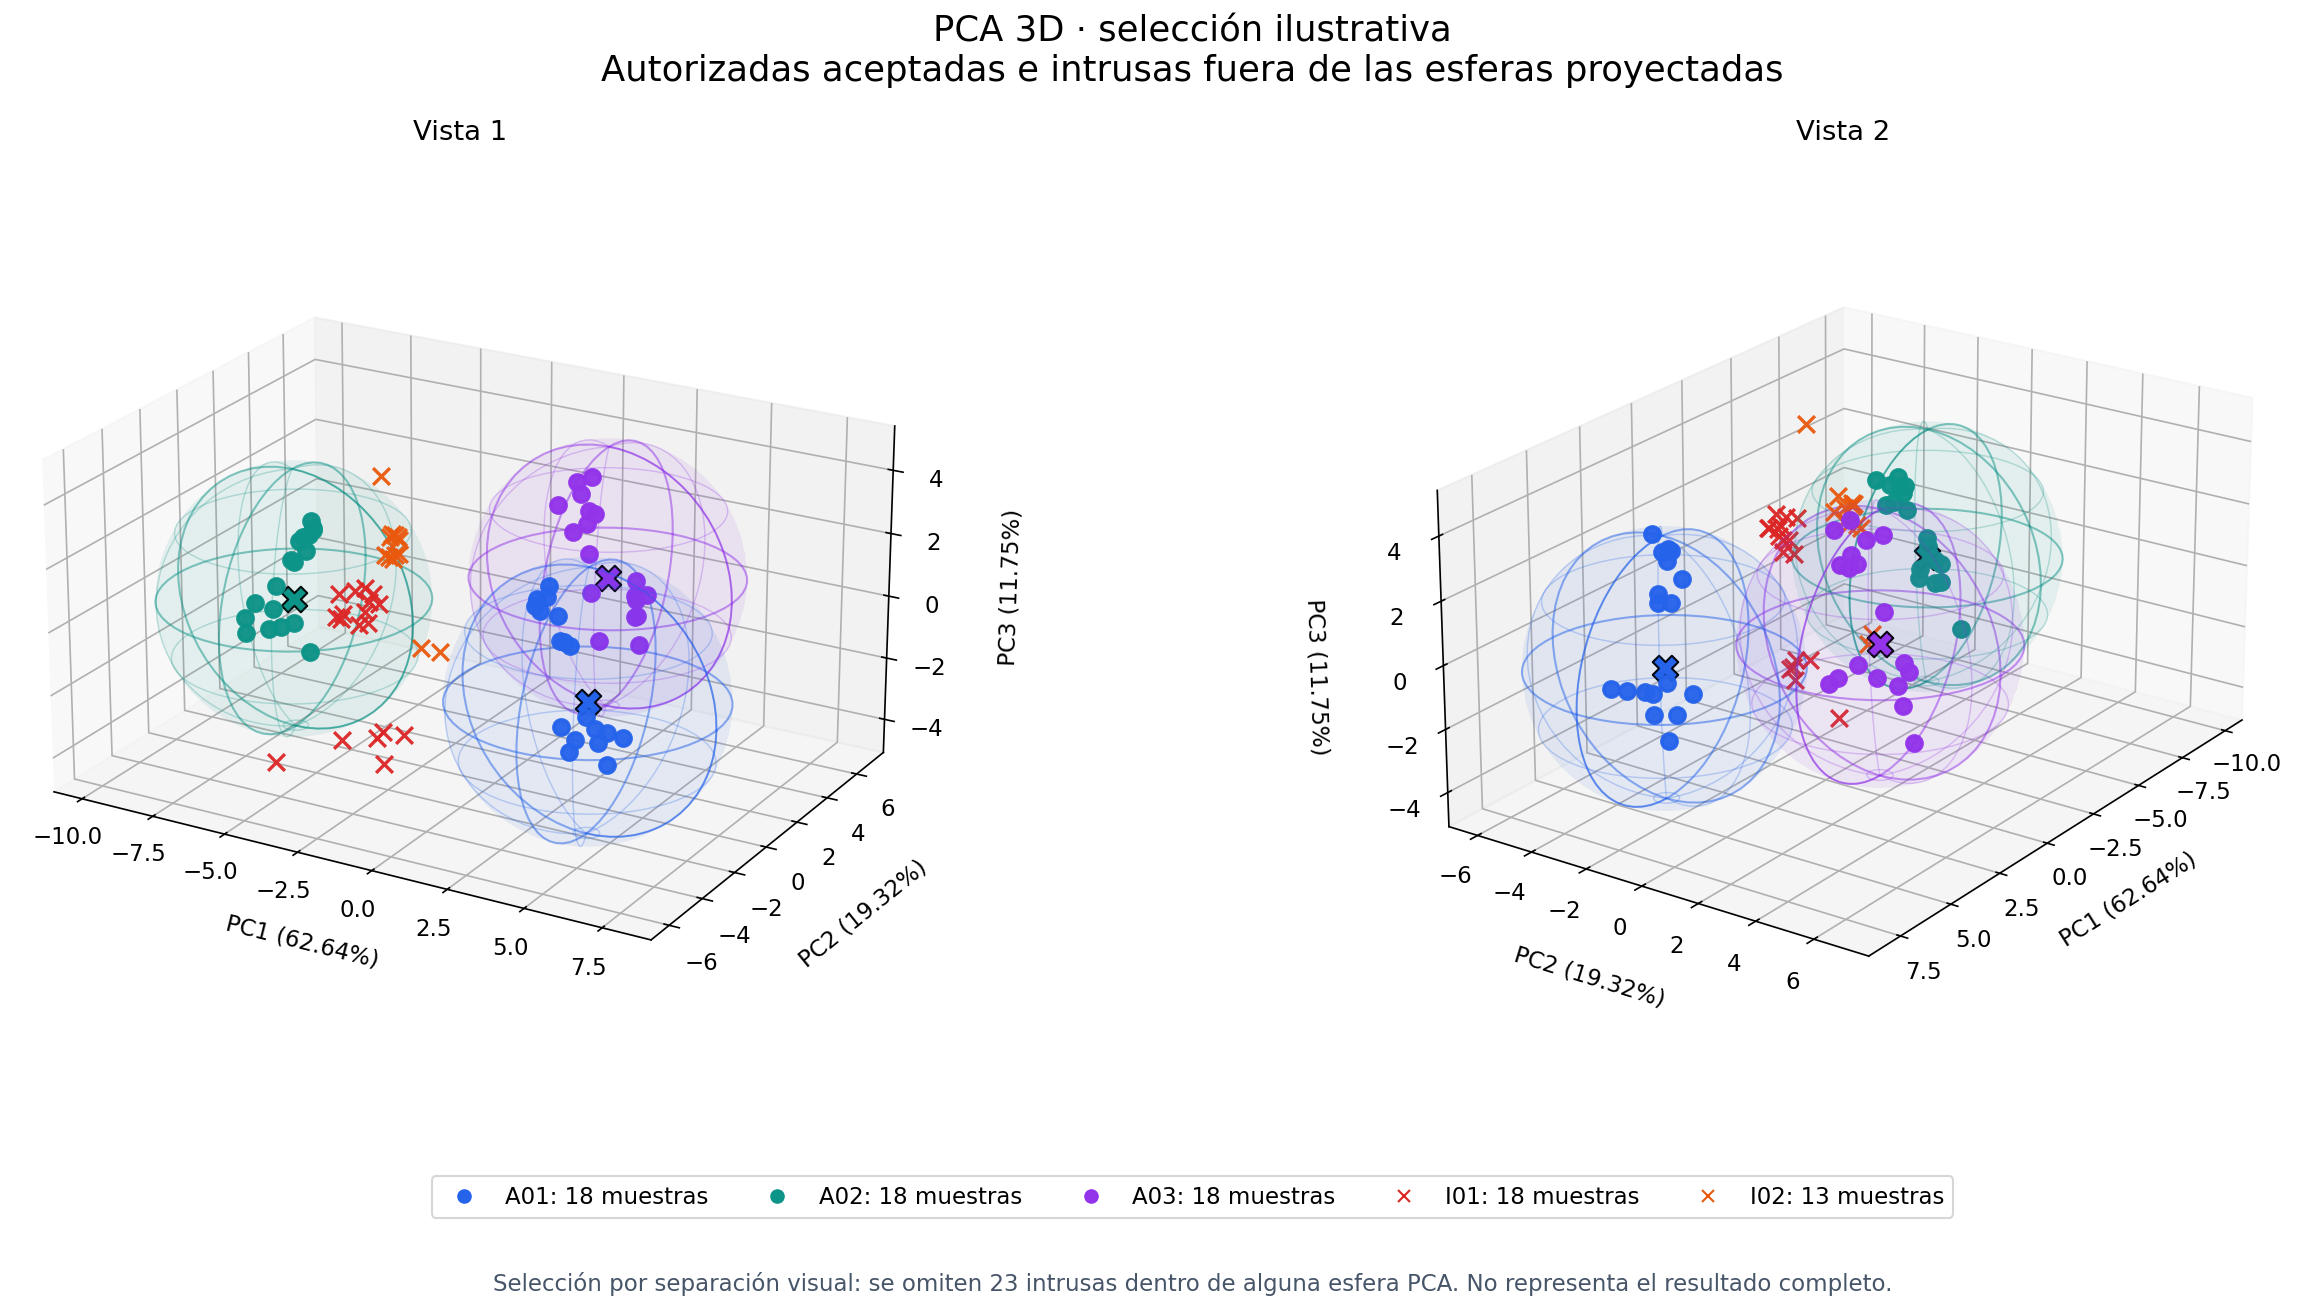

In [2]:
plt.rcParams.update({"font.size":11,"figure.dpi":130})
fig = plt.figure(figsize=(18,9))
u = np.linspace(0,2*np.pi,60)
v = np.linspace(0,np.pi,35)
sx=tau*np.outer(np.cos(u),np.sin(v))
sy=tau*np.outer(np.sin(u),np.sin(v))
sz=tau*np.outer(np.ones_like(u),np.cos(v))
lim_min=np.minimum(P[seleccion,:3].min(0),C[:,:3].min(0)-tau)-0.4
lim_max=np.maximum(P[seleccion,:3].max(0),C[:,:3].max(0)+tau)+0.4
for numero,azimut in enumerate([-60,35],1):
    ax=fig.add_subplot(1,2,numero,projection="3d")
    for g,c in enumerate(C):
        color=colores[mapa[str(g)]]
        ax.plot_surface(sx+c[0],sy+c[1],sz+c[2],color=color,
                        alpha=0.045,shade=False,linewidth=0)
        ax.plot_wireframe(sx+c[0],sy+c[1],sz+c[2],rstride=12,cstride=11,
                          color=color,alpha=0.25,linewidth=0.7)
        # Tres circunferencias para hacer visible la esfera de cada identidad.
        for plano in [0,1,2]:
            curva=np.zeros((len(u),3));dims=[j for j in range(3) if j!=plano]
            curva[:,dims[0]]=tau*np.cos(u);curva[:,dims[1]]=tau*np.sin(u)
            curva+=c[:3]
            ax.plot(curva[:,0],curva[:,1],curva[:,2],color=color,alpha=0.5,lw=1)
        ax.scatter(*c[:3],c=color,marker="X",s=150,edgecolors="black",depthshade=False)
    for identidad,color in colores.items():
        idx=seleccion[ids[seleccion]==identidad]
        autorizada=identidad.startswith("A")
        ax.scatter(P[idx,0],P[idx,1],P[idx,2],c=color,
                   marker="o" if autorizada else "x",s=55 if autorizada else 65,
                   alpha=0.95,depthshade=False,linewidths=1.6)
    ax.set(xlim=(lim_min[0],lim_max[0]),ylim=(lim_min[1],lim_max[1]),zlim=(lim_min[2],lim_max[2]))
    ax.set_box_aspect(lim_max-lim_min)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.2%})",labelpad=12)
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.2%})",labelpad=12)
    ax.set_zlabel(f"PC3 ({pca.explained_variance_ratio_[2]:.2%})",labelpad=12)
    ax.view_init(elev=22,azim=azimut)
    ax.set_title(f"Vista {numero}",pad=18)
leyenda=[Line2D([],[],color=c,marker="o" if i.startswith("A") else "x",ls="",
          label=f"{i}: {(ids[seleccion]==i).sum()} muestras") for i,c in colores.items()]
fig.legend(handles=leyenda,loc="lower center",ncol=5,bbox_to_anchor=(0.5,0.07))
fig.suptitle("PCA 3D · selección ilustrativa\nAutorizadas aceptadas e intrusas fuera de las esferas proyectadas",fontsize=17,y=0.97)
fig.text(0.5,0.025,"Selección por separación visual: se omiten 23 intrusas dentro de alguna esfera PCA. No representa el resultado completo.",ha="center",fontsize=11,color="#475569")
fig.subplots_adjust(left=0.01,right=0.96,bottom=0.19,top=0.85,wspace=0.17)
plt.show()
